In [1]:
import re
import string
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from emotion_classifier.data import LABELS, class_distribution, load_emotion

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "figures"
FIGURES.mkdir( exist_ok = True )

splits = load_emotion()
split_data = {
    "train": ( splits.train_texts, splits.train_labels ),
    "validation": ( splits.val_texts, splits.val_labels ),
    "test": ( splits.test_texts, splits.test_labels ),
}
{ name: len( texts ) for name, ( texts, _ ) in split_data.items() }

/Users/naresh/Documents/Github/emotion-classifier/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'train': 16000, 'validation': 2000, 'test': 2000}

In [2]:
dist = pd.DataFrame( {
    name: class_distribution( labels ) for name, ( _, labels ) in split_data.items()
} )
dist_pct = ( dist / dist.sum() * 100 ).round( 1 )
pd.concat( { "count": dist, "percent": dist_pct }, axis = 1 )

count                 percent                 
         train validation test   train validation  test
sadness   4666        550  581    29.2       27.5  29.0
joy       5362        704  695    33.5       35.2  34.8
love      1304        178  159     8.2        8.9   8.0
anger     2159        275  275    13.5       13.8  13.8
fear      1937        212  224    12.1       10.6  11.2
surprise   572         81   66     3.6        4.0   3.3

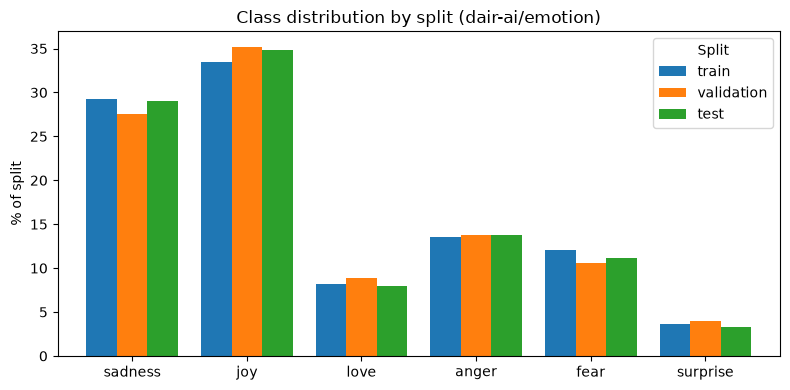

In [3]:
ax = dist_pct.plot.bar( figsize = ( 8, 4 ), rot = 0, width = 0.8 )
ax.set_ylabel( "% of split" )
ax.set_title( "Class distribution by split (dair-ai/emotion)" )
ax.legend( title = "Split" )
plt.tight_layout()
plt.savefig( FIGURES / "class_distribution.png", dpi = 200 )
plt.show()

In [4]:
df_train = pd.DataFrame( { "text": splits.train_texts, "label": [ LABELS[ i ] for i in splits.train_labels ] } )

for label in LABELS:
    print( f"--- {label} ---" )
    for text in df_train[ df_train.label == label ].sample( 3, random_state = 42 ).text:
        print( " ", text )

--- sadness ---
  im feeling so lousy they tried to cheer me up during school time and during choir practice
  i feel highly disadvantaged
  i feel humiliated to introduce you to my colleagues as my wife
--- joy ---
  i feel im rather innocent in that respect
  im feeling quite adventurous and tried out those drinks that i just normally read through the pages of pocketbooks
  im feeling much more positive about the impending move
--- love ---
  i mean fuck i feel like i was way more considerate with customers and concerned about appearance and sanitiation snoozel pm but fine
  i remember a couple of years ago i was feeling romantic and dreamy and asked him wonder if we ll celebrate our th anniversary
  im so going to end up feeling slutty and be like ah
--- anger ---
  i ve been feeling a bit cranky with the kids this week cranky baby whiny year old demanding preschooler so i wanted to stop and remember how blessed i really am
  i feel frustrated sometimes with my mac lipsticks when i 

In [12]:
df_train[ "n_words" ] = df_train.text.str.split().str.len()
df_train.groupby( "label" ).n_words.describe().round( 1 )
# df_train.n_words.describe().round( 1 )

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
anger,2159.0,19.2,11.4,2.0,10.0,17.0,26.0,62.0
fear,1937.0,18.8,10.9,2.0,10.0,17.0,25.0,60.0
joy,5362.0,19.5,10.8,2.0,11.0,18.0,26.0,64.0
love,1304.0,20.7,10.8,3.0,12.0,19.0,27.0,63.0
sadness,4666.0,18.4,11.0,2.0,10.0,16.0,24.0,66.0
surprise,572.0,20.0,11.0,3.0,12.0,18.0,26.0,60.0


In [6]:
from transformers import AutoTokenizer

token_lengths: dict[ str, np.ndarray ] = {}
for model_name in [ "distilbert-base-uncased", "roberta-base" ]:
    tokenizer = AutoTokenizer.from_pretrained( model_name )
    ids = tokenizer( splits.train_texts )[ "input_ids" ]
    token_lengths[ model_name ] = np.array( [ len( seq ) for seq in ids ] )

pd.DataFrame( {
    model_name: { f"p{p}": np.percentile( lengths, p ) for p in [ 50, 90, 95, 99, 99.9, 100 ] }
    for model_name, lengths in token_lengths.items()
} ).round( 0 )

,distilbert-base-uncased,roberta-base
p50,20.0,20.0
p90,38.0,38.0
p95,45.0,45.0
p99,57.0,57.0
p99.9,66.0,66.0
p100,87.0,88.0


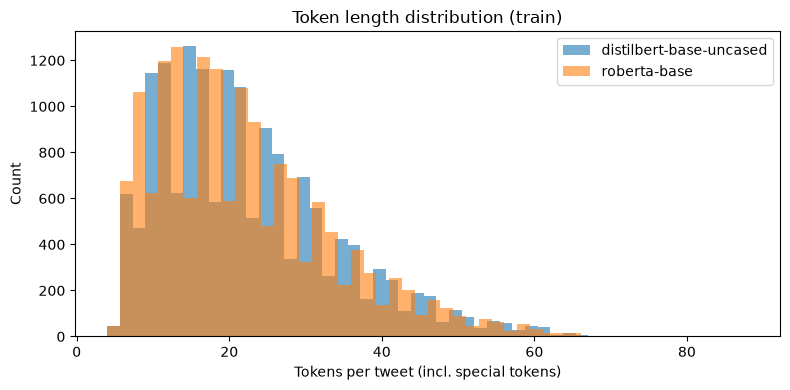

In [7]:
fig, ax = plt.subplots( figsize = ( 8, 4 ) )
for model_name, lengths in token_lengths.items():
    ax.hist( lengths, bins = 50, alpha = 0.6, label = model_name )
ax.set_xlabel( "Tokens per tweet (incl. special tokens)" )
ax.set_ylabel( "Count" )
ax.set_title( "Token length distribution (train)" )
ax.legend()
plt.tight_layout()
plt.savefig( FIGURES / "token_lengths.png", dpi = 200 )
plt.show()

In [8]:
all_texts = splits.train_texts
n_upper = sum( any( c.isupper() for c in text ) for text in all_texts )
punct = Counter( c for text in all_texts for c in text if c in string.punctuation )
starts_i_feel = np.mean( [ text.startswith( "i feel" ) for text in all_texts ] )
has_feel = np.mean( [ bool( re.search( r"\bfeel", text ) ) for text in all_texts ] )

print( f"tweets with any uppercase: {n_upper}" )
print( f"punctuation counts: {punct.most_common( 10 )}" )
print( f"start with 'i feel': {starts_i_feel:.1%}" )
print( f"contain 'feel*': {has_feel:.1%}" )

tweets with any uppercase: 0
punctuation counts: []
start with 'i feel': 31.9%
contain 'feel*': 98.7%


In [9]:
train_set = set( splits.train_texts )
print( "duplicate texts in train:", len( splits.train_texts ) - len( train_set ) )
print( "test texts also in train:", sum( text in train_set for text in splits.test_texts ) )
print( "val texts also in train:", sum( text in train_set for text in splits.val_texts ) )

labels_per_text = df_train.groupby( "text" ).label.nunique()
conflicts = labels_per_text[ labels_per_text > 1 ]
print( "texts with conflicting labels in train:", len( conflicts ) )
df_train[ df_train.text.isin( conflicts.index ) ].sort_values( "text" ).head( 10 )

duplicate texts in train: 31
test texts also in train: 11
val texts also in train: 5
texts with conflicting labels in train: 30


,text,label,n_words
3508,i am not amazing or great at photography but i...,joy,14
8246,i am not amazing or great at photography but i...,love,14
5277,i began to feel accepted by gaia on her own terms,love,11
15705,i began to feel accepted by gaia on her own terms,joy,11
8804,i bet taylor swift basks in the knowledge that...,fear,18
15572,i bet taylor swift basks in the knowledge that...,anger,18
11013,i cant escape the tears of sadness and just tr...,love,22
12892,i cant escape the tears of sadness and just tr...,joy,22
13653,i could feel myself hit this strange foggy wall,fear,9
14314,i could feel myself hit this strange foggy wall,surprise,9


In [10]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer( stop_words = "english" )
X = vectorizer.fit_transform( splits.train_texts )
vocab = np.array( vectorizer.get_feature_names_out() )
labels_arr = np.array( splits.train_labels )

pd.DataFrame( {
    label: vocab[ np.asarray( X[ labels_arr == i ].sum( axis = 0 ) ).ravel().argsort()[ ::-1 ][ :10 ] ]
    for i, label in enumerate( LABELS )
} )
print( "vocabulary size (train, no stop words):", len( vocab ) )

vocabulary size (train, no stop words): 14894


## Findings (for the report)

**Splits:** train 16,000 / validation 2,000 / test 2,000 (official `split` config).

**Class balance (train):**

| emotion | count (train) | count (val) | count (test) | % train | % val | % test |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| sadness | 4666 | 550 | 581 | 29.2 | 27.5 | 29.0 |
| joy | 5362 | 704 | 695 | 33.5 | 35.2 | 34.8 |
| love | 1304 | 178 | 159 | 8.2 | 8.9 | 8.0 |
| anger | 2159 | 275 | 275 | 13.5 | 13.8 | 13.8 |
| fear | 1937 | 212 | 224 | 12.1 | 10.6 | 11.2 |
| surprise | 572 | 81 | 66 | 3.6 | 4.0 | 3.3 |

- Rarest class: **surprise 3.6%** vs largest **joy 33.5%** → ~**9.4× imbalance** → macro-F1 as headline metric.
- Love (8.2%) is the second minority class.

**Consistent across splits:** yes, max difference **1.7 points** for any class (joy, sadness).
- Caveat: only **66 surprise** examples in test, so per-class F1 for surprise will be volatile.

**Words per tweet (train):** class medians **16–19**, max **66**.
- Love/surprise slightly longer on average (~20–21 vs 18–19). Difference too small to be a useful shortcut.

**Token lengths (train):**
- distilbert-base-uncased: p99 = __, max = __
- roberta-base: p99 = __, max = __
- **Chosen `max_length` = __** (max rounded up to a multiple of 8 → no truncation; dynamic padding keeps the cost low)

![Token length distribution](../figures/token_lengths.png)

**Preprocessing already applied in source:**
- Uppercase characters: **0** → fully lowercased.
- Punctuation: **none**, not even apostrophes → contractions appear as `im`, `dont`, `didnt`.
- Implications:
  - Stop-word lists won't remove `dont` / `didnt`, but will remove `not` (relevant to the E2 ablation).
  - Text differs from transformer pre-training data (cased, punctuated); RoBERTa (cased) is the more affected.

**"Feel" pattern (collection bias):**
- Contain "feel…": **98.7%**
- Start with "i feel": **31.9%**
- → Tweets were likely collected via feeling-phrase queries.
  - "feel" carries no class information → supports TF-IDF down-weighting.
  - Models only ever see explicit "I feel…" phrasing → generalisation to other emotional text is unproven.

**Duplicates, leakage, label noise:**
- Duplicate texts in train: **31**
- Texts with conflicting labels in train: **30** → almost every duplicate carries a *different* emotion (likely multi-hashtag tweets collected once per hashtag).
  - Direct evidence of label noise; caps achievable accuracy below 100%.
- Test texts also in train: **11 (0.55%)**; val texts also in train: **5 (0.25%)**.
  - Decision: keep official splits for comparability with published results; impact ≤ ~0.5 points. Report in Experimental Setup.

**Interesting examples (label noise / ambiguity):**
- "__" → labelled __ and __
- "__" → labelled __ (arguably __)